# Run Testing Pipeline For Latest SI Models Across All Modalities

This notebook runs the same prediction/evaluation path used by `run_testing_pipeline.py` across the latest SI experiment runs for every model and modality. It uses the testing videos in `Dataset/testing`, selects the current 30-frame runs, and compares results by model and modality.


In [21]:
from __future__ import annotations

import json
import re
import traceback
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training.config import ALLOWED_MODALITIES, ALLOWED_MODELS, ExperimentConfig
from training.testing_pipeline import evaluate_prediction, load_label_map, predict_video, resolve_run_dir

pd.set_option("display.max_colwidth", 120)


## Settings

In [22]:
DATASET_DIR = Path("Dataset/testing")
ARTIFACTS_DIR = Path("artifacts")
EXPERIMENTS_DIR = ARTIFACTS_DIR / "experiments"
OUTPUT_DIR = ARTIFACTS_DIR / "testing_pipeline_all_models"

SCENARIOS = ("si",)
MODELS = tuple(ALLOWED_MODELS)
MODALITIES = tuple(ALLOWED_MODALITIES)
TOP_K = 5

# Leave as None to evaluate every video. Set to a small integer for a quick smoke test.
MAX_VIDEOS = None

# Leave empty to test every discovered run. Otherwise paste run directories or .weights.h5 paths here.
# Each path represents one model/scenario/modality/frame-sample run.
MODEL_PATHS = [
    # "artifacts/experiments/si/transformer/body_hand_face/20260619T025735Z",
    # "artifacts/experiments/si/transformer/body_hand_face/20260619T025735Z/best.weights.h5",
]

# The latest all-modality SI training process uses 30 sampled frames.
FRAME_SAMPLE_COUNTS = {30}

# How to handle multiple runs with the same scenario/model/modality/frame_sample_count.
# Use "latest" for the newest run_id, or "best" for the highest summary metric.
RUN_SELECTION_STRATEGY = "latest"
BEST_SUMMARY_METRIC = "f1_score"  # Used only when RUN_SELECTION_STRATEGY = "best". Lower "loss" is handled automatically.

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Testing videos: {DATASET_DIR}")
print(f"Experiments: {EXPERIMENTS_DIR}")
print(f"Scenarios: {SCENARIOS}")
print(f"Modalities: {MODALITIES}")
print(f"Outputs: {OUTPUT_DIR}")


Testing videos: Dataset/testing
Experiments: artifacts/experiments
Scenarios: ('si',)
Modalities: ('hand', 'hand_body', 'hand_face', 'body_hand_face')
Outputs: artifacts/testing_pipeline_all_models


## Discover Videos And Experiment Runs

In [23]:
def normalize_label_from_video_name(video_path: Path) -> str | None:
    """Infer a gloss label from names like 123456-GO TO_JAIL.mp4 -> GOTOJAIL."""
    stem = video_path.stem
    if "-" not in stem:
        return None
    raw_label = stem.split("-", 1)[1]
    return re.sub(r"[\s_]+", "", raw_label).upper()


def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding="utf-8"))


def discover_videos(dataset_dir: Path, max_videos: int | None = None) -> list[Path]:
    videos = sorted(path for path in dataset_dir.glob("*.mp4") if path.is_file())
    if max_videos is not None:
        videos = videos[:max_videos]
    return videos


def run_row_from_path(model_path: Path) -> dict:
    run_dir = resolve_run_dir(model_path)
    config_path = run_dir / "config.json"
    config = read_json(config_path)
    summary_path = run_dir / "summary.json"
    summary = read_json(summary_path) if summary_path.exists() else {}
    metrics = summary.get("metrics", {}) if isinstance(summary.get("metrics", {}), dict) else {}
    weights_path = model_path if model_path.is_file() and model_path.name.endswith(".weights.h5") else None
    if weights_path is None:
        weights_path = run_dir / "best.weights.h5" if (run_dir / "best.weights.h5").exists() else run_dir / "final.weights.h5"
    return {
        "scenario": str(config.get("scenario", "")),
        "model": str(config.get("model", "")),
        "modality": str(config.get("modality", "")),
        "frame_sample_count": int(config.get("frame_sample_count", -1)),
        "run_id": run_dir.name,
        "run_dir": run_dir,
        "config_path": config_path,
        "summary_path": summary_path if summary_path.exists() else None,
        "weights_path": weights_path,
        "input_shape": tuple(config.get("input_shape", [])),
        "num_classes": config.get("num_classes"),
        "summary_accuracy": metrics.get("accuracy"),
        "summary_f1_score": metrics.get("f1_score"),
        "summary_loss": metrics.get("loss"),
    }


def discover_runs(
    experiments_dir: Path,
    scenarios: tuple[str, ...],
    models: tuple[str, ...],
    modalities: tuple[str, ...],
    frame_sample_counts: set[int] | None = None,
) -> pd.DataFrame:
    rows = []
    for scenario in scenarios:
        for model in models:
            for modality in modalities:
                model_dir = experiments_dir / scenario / model / modality
                for config_path in sorted(model_dir.glob("*/config.json")):
                    run_dir = config_path.parent
                    config = read_json(config_path)
                    frame_sample_count = int(config.get("frame_sample_count", -1))
                    if frame_sample_counts is not None and frame_sample_count not in frame_sample_counts:
                        continue
                    rows.append(run_row_from_path(run_dir))
    if not rows:
        return pd.DataFrame()
    return pd.DataFrame(rows).sort_values(["scenario", "model", "modality", "frame_sample_count", "run_id"]).reset_index(drop=True)


def runs_from_model_paths(model_paths: list[str | Path]) -> pd.DataFrame:
    rows = [run_row_from_path(Path(path)) for path in model_paths]
    if not rows:
        return pd.DataFrame()
    return pd.DataFrame(rows).sort_values(["scenario", "model", "modality", "frame_sample_count", "run_id"]).reset_index(drop=True)


def select_preferred_runs(runs: pd.DataFrame, strategy: str, best_metric: str) -> pd.DataFrame:
    if runs.empty:
        return runs

    key_columns = ["scenario", "model", "modality", "frame_sample_count"]
    strategy = strategy.lower().strip()
    if strategy == "latest":
        selected = runs.sort_values(key_columns + ["run_id"]).groupby(key_columns, as_index=False, dropna=False).tail(1)
    elif strategy == "best":
        metric_column = f"summary_{best_metric}"
        if metric_column not in runs.columns:
            raise ValueError(f"Unknown summary metric: {best_metric!r}. Expected a column named {metric_column!r}.")
        ascending = best_metric != "loss"
        sort_columns = key_columns + [metric_column, "run_id"]
        selected = (
            runs.sort_values(sort_columns, ascending=[True, True, True, True, ascending, True], na_position="first")
            .groupby(key_columns, as_index=False, dropna=False)
            .tail(1)
        )
    else:
        raise ValueError("RUN_SELECTION_STRATEGY must be 'latest' or 'best'.")

    return selected.sort_values(key_columns).reset_index(drop=True)


selected_sample_counts = None if FRAME_SAMPLE_COUNTS is None else {int(value) for value in FRAME_SAMPLE_COUNTS}
videos = discover_videos(DATASET_DIR, MAX_VIDEOS)
all_runs_df = discover_runs(EXPERIMENTS_DIR, SCENARIOS, MODELS, MODALITIES, selected_sample_counts)
candidate_runs_df = runs_from_model_paths(MODEL_PATHS) if MODEL_PATHS else all_runs_df.copy()
runs_df = select_preferred_runs(candidate_runs_df, RUN_SELECTION_STRATEGY, BEST_SUMMARY_METRIC)

print(f"Videos discovered: {len(videos)}")
print(f"Experiment runs discovered: {len(all_runs_df)}")
print(f"Experiment run candidates: {len(candidate_runs_df)}")
print(f"Experiment runs selected for testing: {len(runs_df)} ({RUN_SELECTION_STRATEGY}, metric={BEST_SUMMARY_METRIC})")

model_path_list_df = all_runs_df[["scenario", "model", "modality", "frame_sample_count", "run_id", "summary_accuracy", "summary_f1_score", "summary_loss", "run_dir", "weights_path"]].copy()
model_path_list_df["run_dir"] = model_path_list_df["run_dir"].astype(str)
model_path_list_df["weights_path"] = model_path_list_df["weights_path"].astype(str)
display(model_path_list_df)

print("Selected runs:")
display(runs_df)


Videos discovered: 55
Experiment runs discovered: 47
Experiment run candidates: 47
Experiment runs selected for testing: 16 (latest, metric=f1_score)


,scenario,model,modality,frame_sample_count,run_id,summary_accuracy,summary_f1_score,summary_loss,run_dir,weights_path
0,si,cnn1d,body_hand_face,30,20260608T095025Z,0.019914,1.176026e-02,7.333051,artifacts/experiments/si/cnn1d/body_hand_face/20260608T095025Z,artifacts/experiments/si/cnn1d/body_hand_face/20260608T095025Z/best.weights.h5
1,si,cnn1d,body_hand_face,30,20260615T034844Z,0.092468,8.713509e-02,5.913048,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z/best.weights.h5
2,si,cnn1d,hand,30,20260504T163204Z,0.181567,1.679984e-01,4.896591,artifacts/experiments/si/cnn1d/hand/20260504T163204Z,artifacts/experiments/si/cnn1d/hand/20260504T163204Z/best.weights.h5
3,si,cnn1d,hand,30,20260526T164250Z,0.185544,1.726282e-01,4.819768,artifacts/experiments/si/cnn1d/hand/20260526T164250Z,artifacts/experiments/si/cnn1d/hand/20260526T164250Z/best.weights.h5
4,si,cnn1d,hand,30,20260609T023654Z,0.115358,1.019868e-01,6.360775,artifacts/experiments/si/cnn1d/hand/20260609T023654Z,artifacts/experiments/si/cnn1d/hand/20260609T023654Z/best.weights.h5
5,si,cnn1d,hand,30,20260614T174802Z,0.259342,2.549434e-01,5.071100,artifacts/experiments/si/cnn1d/hand/20260614T174802Z,artifacts/experiments/si/cnn1d/hand/20260614T174802Z/best.weights.h5
6,si,cnn1d,hand_body,30,20260526T011219Z,0.230564,2.189091e-01,4.217395,artifacts/experiments/si/cnn1d/hand_body/20260526T011219Z,artifacts/experiments/si/cnn1d/hand_body/20260526T011219Z/best.weights.h5
7,si,cnn1d,hand_body,30,20260610T065456Z,0.120306,1.076659e-01,6.679178,artifacts/experiments/si/cnn1d/hand_body/20260610T065456Z,artifacts/experiments/si/cnn1d/hand_body/20260610T065456Z/best.weights.h5
8,si,cnn1d,hand_body,30,20260614T201315Z,0.301661,2.990072e-01,4.928476,artifacts/experiments/si/cnn1d/hand_body/20260614T201315Z,artifacts/experiments/si/cnn1d/hand_body/20260614T201315Z/best.weights.h5
9,si,cnn1d,hand_face,30,20260614T225317Z,0.081783,7.652264e-02,6.128114,artifacts/experiments/si/cnn1d/hand_face/20260614T225317Z,artifacts/experiments/si/cnn1d/hand_face/20260614T225317Z/best.weights.h5


Selected runs:


,scenario,model,modality,frame_sample_count,run_id,run_dir,config_path,summary_path,weights_path,input_shape,num_classes,summary_accuracy,summary_f1_score,summary_loss
0,si,cnn1d,body_hand_face,30,20260615T034844Z,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z/config.json,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z/summary.json,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z/best.weights.h5,"(30, 2765)",2731,0.092468,0.087135,5.913048
1,si,cnn1d,hand,30,20260614T174802Z,artifacts/experiments/si/cnn1d/hand/20260614T174802Z,artifacts/experiments/si/cnn1d/hand/20260614T174802Z/config.json,artifacts/experiments/si/cnn1d/hand/20260614T174802Z/summary.json,artifacts/experiments/si/cnn1d/hand/20260614T174802Z/best.weights.h5,"(30, 210)",2731,0.259342,0.254943,5.071100
2,si,cnn1d,hand_body,30,20260614T201315Z,artifacts/experiments/si/cnn1d/hand_body/20260614T201315Z,artifacts/experiments/si/cnn1d/hand_body/20260614T201315Z/config.json,artifacts/experiments/si/cnn1d/hand_body/20260614T201315Z/summary.json,artifacts/experiments/si/cnn1d/hand_body/20260614T201315Z/best.weights.h5,"(30, 375)",2731,0.301661,0.299007,4.928476
3,si,cnn1d,hand_face,30,20260614T225317Z,artifacts/experiments/si/cnn1d/hand_face/20260614T225317Z,artifacts/experiments/si/cnn1d/hand_face/20260614T225317Z/config.json,artifacts/experiments/si/cnn1d/hand_face/20260614T225317Z/summary.json,artifacts/experiments/si/cnn1d/hand_face/20260614T225317Z/best.weights.h5,"(30, 2600)",2731,0.081783,0.076523,6.128114
4,si,gcn,body_hand_face,30,20260619T221441Z,artifacts/experiments/si/gcn/body_hand_face/20260619T221441Z,artifacts/experiments/si/gcn/body_hand_face/20260619T221441Z/config.json,artifacts/experiments/si/gcn/body_hand_face/20260619T221441Z/summary.json,artifacts/experiments/si/gcn/body_hand_face/20260619T221441Z/best.weights.h5,"(30, 2765)",2731,0.301448,0.298862,3.998196
5,si,gcn,hand,30,20260619T103334Z,artifacts/experiments/si/gcn/hand/20260619T103334Z,artifacts/experiments/si/gcn/hand/20260619T103334Z/config.json,artifacts/experiments/si/gcn/hand/20260619T103334Z/summary.json,artifacts/experiments/si/gcn/hand/20260619T103334Z/best.weights.h5,"(30, 210)",2731,0.272639,0.265440,4.427376
6,si,gcn,hand_body,30,20260619T132838Z,artifacts/experiments/si/gcn/hand_body/20260619T132838Z,artifacts/experiments/si/gcn/hand_body/20260619T132838Z/config.json,artifacts/experiments/si/gcn/hand_body/20260619T132838Z/summary.json,artifacts/experiments/si/gcn/hand_body/20260619T132838Z/best.weights.h5,"(30, 375)",2731,0.300325,0.296853,4.141792
7,si,gcn,hand_face,30,20260619T163429Z,artifacts/experiments/si/gcn/hand_face/20260619T163429Z,artifacts/experiments/si/gcn/hand_face/20260619T163429Z/config.json,artifacts/experiments/si/gcn/hand_face/20260619T163429Z/summary.json,artifacts/experiments/si/gcn/hand_face/20260619T163429Z/best.weights.h5,"(30, 2600)",2731,0.191524,0.185000,5.236109
8,si,lstm,body_hand_face,30,20260620T045322Z,artifacts/experiments/si/lstm/body_hand_face/20260620T045322Z,artifacts/experiments/si/lstm/body_hand_face/20260620T045322Z/config.json,artifacts/experiments/si/lstm/body_hand_face/20260620T045322Z/summary.json,artifacts/experiments/si/lstm/body_hand_face/20260620T045322Z/best.weights.h5,"(30, 2765)",2731,0.159922,0.150777,4.732775
9,si,lstm,hand,30,20260615T093525Z,artifacts/experiments/si/lstm/hand/20260615T093525Z,artifacts/experiments/si/lstm/hand/20260615T093525Z/config.json,artifacts/experiments/si/lstm/hand/20260615T093525Z/summary.json,artifacts/experiments/si/lstm/hand/20260615T093525Z/best.weights.h5,"(30, 210)",2731,0.312984,0.309110,4.429760


In [24]:
if not videos:
    raise FileNotFoundError(f"No .mp4 videos found in {DATASET_DIR}")
if runs_df.empty:
    raise FileNotFoundError(f"No experiment runs found under {EXPERIMENTS_DIR}")

video_df = pd.DataFrame(
    {
        "video": videos,
        "video_name": [path.name for path in videos],
        "expected_label": [normalize_label_from_video_name(path) for path in videos],
    }
)
display(video_df.head(20))


,video,video_name,expected_label
0,Dataset/testing/019809089337332608-HEAP.mp4,019809089337332608-HEAP.mp4,HEAP
1,Dataset/testing/04044336822636918-SNOB.mp4,04044336822636918-SNOB.mp4,SNOB
2,Dataset/testing/042428497095387874-TEAR RIP_2.mp4,042428497095387874-TEAR RIP_2.mp4,TEARRIP2
3,Dataset/testing/08357883202605598-BACK UP.mp4,08357883202605598-BACK UP.mp4,BACKUP
4,Dataset/testing/10197122928088187-GRENADE.mp4,10197122928088187-GRENADE.mp4,GRENADE
5,Dataset/testing/12448238042056992-SEQUENCE.mp4,12448238042056992-SEQUENCE.mp4,SEQUENCE
6,Dataset/testing/1461714441572386-GRIND.mp4,1461714441572386-GRIND.mp4,GRIND
7,Dataset/testing/16186397288837262-SUSHI.mp4,16186397288837262-SUSHI.mp4,SUSHI
8,Dataset/testing/16570823618121522-CASTLE.mp4,16570823618121522-CASTLE.mp4,CASTLE
9,Dataset/testing/18508791786058-GRADUATE1.mp4,18508791786058-GRADUATE1.mp4,GRADUATE1


## Run All Predictions

This cell can take a while because each row runs video landmark extraction and model inference. Results are checkpointed to JSONL as they finish, so a long run still leaves useful output if it is interrupted.

In [25]:
timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
jsonl_path = OUTPUT_DIR / f"testing_pipeline_predictions_{timestamp}.jsonl"
csv_path = OUTPUT_DIR / f"testing_pipeline_predictions_{timestamp}.csv"
summary_path = OUTPUT_DIR / f"testing_pipeline_summary_{timestamp}.csv"

records = []
total = len(runs_df) * len(video_df)
completed = 0

with jsonl_path.open("w", encoding="utf-8") as jsonl_file:
    for run in runs_df.itertuples(index=False):
        print(
            f"\n=== {run.scenario} | {run.model} | {run.modality} | "
            f"frames={run.frame_sample_count} | run={run.run_id} ==="
        )
        for video in video_df.itertuples(index=False):
            completed += 1
            print(f"[{completed}/{total}] {video.video_name}")
            try:
                result = predict_video(video.video, run.run_dir, top_k=TOP_K)
                result = evaluate_prediction(result, video.expected_label)
                top_prediction = result["top_predictions"][0]
                record = {
                    "ok": True,
                    "scenario": result["scenario"],
                    "model": result["model"],
                    "modality": result["modality"],
                    "frame_sample_count": result["frame_sample_count"],
                    "run_id": run.run_id,
                    "run_dir": result["run_dir"],
                    "weights_path": result["weights_path"],
                    "video_path": result["video_path"],
                    "video_name": video.video_name,
                    "expected_label": result["expected_label"],
                    "prediction": top_prediction["label"],
                    "prediction_index": top_prediction["index"],
                    "confidence": top_prediction["confidence"],
                    "correct": result["correct"],
                    "top_predictions": result["top_predictions"],
                    "error": None,
                }
            except Exception as exc:
                record = {
                    "ok": False,
                    "scenario": run.scenario,
                    "model": run.model,
                    "modality": run.modality,
                    "frame_sample_count": run.frame_sample_count,
                    "run_id": run.run_id,
                    "run_dir": str(run.run_dir),
                    "weights_path": str(run.weights_path),
                    "video_path": str(video.video),
                    "video_name": video.video_name,
                    "expected_label": video.expected_label,
                    "prediction": None,
                    "prediction_index": None,
                    "confidence": None,
                    "correct": None,
                    "top_predictions": [],
                    "error": "".join(traceback.format_exception_only(type(exc), exc)).strip(),
                }
            records.append(record)
            jsonl_file.write(json.dumps(record, ensure_ascii=False) + "\n")
            jsonl_file.flush()

results_df = pd.DataFrame(records)
results_df.to_csv(csv_path, index=False)
print(f"\nSaved detailed JSONL: {jsonl_path}")
print(f"Saved detailed CSV: {csv_path}")
display(results_df.head())



=== si | cnn1d | body_hand_face | frames=30 | run=20260615T034844Z ===
[1/880] 019809089337332608-HEAP.mp4


W0000 00:00:1782064271.387508  128568 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782064271.603236  128570 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782064271.729788  128587 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782064271.794807  128583 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782064271.805167  128593 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1782064271.837446  128606 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. 

[2/880] 04044336822636918-SNOB.mp4


W0000 00:00:1782064275.334560  128634 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782064275.560156  128635 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782064275.632096  128649 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782064275.650007  128649 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782064275.651711  128659 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1782064275.663470  128663 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. 

[3/880] 042428497095387874-TEAR RIP_2.mp4


W0000 00:00:1782064278.541020  128704 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782064278.570864  128708 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782064278.679440  128714 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782064278.725029  128714 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782064278.726823  128725 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1782064278.731647  128727 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. 

... (1,752 outputs left out)

[880/880] 9725091268498984-REQUEST.mp4


W0000 00:00:1782066119.389346  174277 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782066119.394345  174277 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782066119.395651  174287 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1782066119.399434  174293 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782066119.404475  174291 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.



Saved detailed JSONL: artifacts/testing_pipeline_all_models/testing_pipeline_predictions_20260621T175110Z.jsonl
Saved detailed CSV: artifacts/testing_pipeline_all_models/testing_pipeline_predictions_20260621T175110Z.csv


,ok,scenario,model,modality,frame_sample_count,run_id,run_dir,weights_path,video_path,video_name,expected_label,prediction,prediction_index,confidence,correct,top_predictions,error
0,True,si,cnn1d,body_hand_face,30,20260615T034844Z,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z/best.weights.h5,Dataset/testing/019809089337332608-HEAP.mp4,019809089337332608-HEAP.mp4,HEAP,KNIGHT1,1312,0.324770,False,"[{'rank': 1, 'label': 'KNIGHT1', 'index': 1312, 'confidence': 0.3247695565223694}, {'rank': 2, 'label': 'STRIPE', 'i...",None
1,True,si,cnn1d,body_hand_face,30,20260615T034844Z,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z/best.weights.h5,Dataset/testing/04044336822636918-SNOB.mp4,04044336822636918-SNOB.mp4,SNOB,BOTTLE,254,0.213079,False,"[{'rank': 1, 'label': 'BOTTLE', 'index': 254, 'confidence': 0.2130792886018753}, {'rank': 2, 'label': 'PICK', 'index...",None
2,True,si,cnn1d,body_hand_face,30,20260615T034844Z,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z/best.weights.h5,Dataset/testing/042428497095387874-TEAR RIP_2.mp4,042428497095387874-TEAR RIP_2.mp4,TEARRIP2,MESS,1480,0.300794,False,"[{'rank': 1, 'label': 'MESS', 'index': 1480, 'confidence': 0.3007943332195282}, {'rank': 2, 'label': 'JUGGLE', 'inde...",None
3,True,si,cnn1d,body_hand_face,30,20260615T034844Z,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z/best.weights.h5,Dataset/testing/08357883202605598-BACK UP.mp4,08357883202605598-BACK UP.mp4,BACKUP,GREET1,1049,0.184796,False,"[{'rank': 1, 'label': 'GREET1', 'index': 1049, 'confidence': 0.18479566276073456}, {'rank': 2, 'label': 'EGGBEATER',...",None
4,True,si,cnn1d,body_hand_face,30,20260615T034844Z,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z,artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z/best.weights.h5,Dataset/testing/10197122928088187-GRENADE.mp4,10197122928088187-GRENADE.mp4,GRENADE,NIECE,1579,0.070004,False,"[{'rank': 1, 'label': 'NIECE', 'index': 1579, 'confidence': 0.07000354677438736}, {'rank': 2, 'label': 'RAZOR1', 'in...",None


## Summaries

In [26]:
if "results_df" not in globals():
    latest_jsonl = sorted(OUTPUT_DIR.glob("testing_pipeline_predictions_*.jsonl"))[-1]
    results_df = pd.read_json(latest_jsonl, lines=True)
    print(f"Loaded {latest_jsonl}")
    summary_path = OUTPUT_DIR / latest_jsonl.name.replace("testing_pipeline_predictions_", "testing_pipeline_summary_").replace(".jsonl", ".csv")


def macro_f1_score_from_group(group: pd.DataFrame) -> float:
    valid = group[group["ok"] & group["expected_label"].notna() & group["prediction"].notna()]
    if valid.empty:
        return np.nan

    labels = sorted(set(valid["expected_label"]) | set(valid["prediction"]))
    f1_scores = []
    for label in labels:
        y_true = valid["expected_label"] == label
        y_pred = valid["prediction"] == label
        true_positive = int((y_true & y_pred).sum())
        false_positive = int((~y_true & y_pred).sum())
        false_negative = int((y_true & ~y_pred).sum())
        precision = true_positive / (true_positive + false_positive) if (true_positive + false_positive) else 0.0
        recall = true_positive / (true_positive + false_negative) if (true_positive + false_negative) else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
        f1_scores.append(f1)
    return float(np.mean(f1_scores))


summary_df = (
    results_df.assign(correct_numeric=results_df["correct"].map({True: 1, False: 0}))
    .groupby(["scenario", "model", "modality", "frame_sample_count", "run_id"], dropna=False)
    .agg(
        videos=("video_name", "count"),
        successful=("ok", "sum"),
        errors=("ok", lambda values: int((~values).sum())),
        accuracy=("correct_numeric", "mean"),
        mean_confidence=("confidence", "mean"),
    )
    .reset_index()
    .sort_values(["scenario", "frame_sample_count", "accuracy", "model"], ascending=[True, True, False, True])
)
f1_df = (
    results_df.groupby(["scenario", "model", "modality", "frame_sample_count", "run_id"], dropna=False)
    .apply(macro_f1_score_from_group)
    .rename("macro_f1")
    .reset_index()
)
summary_df = summary_df.merge(f1_df, on=["scenario", "model", "modality", "frame_sample_count", "run_id"], how="left")

summary_df.to_csv(summary_path, index=False)
print(f"Saved summary CSV: {summary_path}")
display(summary_df)


Saved summary CSV: artifacts/testing_pipeline_all_models/testing_pipeline_summary_20260621T175110Z.csv


,scenario,model,modality,frame_sample_count,run_id,videos,successful,errors,accuracy,mean_confidence,macro_f1
0,si,transformer,hand_body,30,20260618T155746Z,55,55,0,0.290909,0.483472,0.174074
1,si,transformer,body_hand_face,30,20260619T025735Z,55,55,0,0.272727,0.480144,0.159574
2,si,transformer,hand,30,20260618T112822Z,55,55,0,0.272727,0.588965,0.157706
3,si,lstm,hand,30,20260615T093525Z,55,55,0,0.181818,0.506399,0.098639
4,si,lstm,hand_body,30,20260615T233635Z,55,55,0,0.181818,0.508198,0.097643
5,si,cnn1d,hand,30,20260614T174802Z,55,55,0,0.163636,0.409404,0.091837
6,si,cnn1d,hand_body,30,20260614T201315Z,55,55,0,0.163636,0.501411,0.086667
7,si,gcn,hand_body,30,20260619T132838Z,55,55,0,0.145455,0.366988,0.080000
8,si,transformer,hand_face,30,20260618T200259Z,55,55,0,0.145455,0.330478,0.079208
9,si,gcn,hand,30,20260619T103334Z,55,55,0,0.127273,0.343384,0.069307


## Testing Pipeline Accuracy And F1 Bar Charts

These charts use `summary_df`, so they reflect the current testing pipeline predictions over `Dataset/testing`.

,scenario,model,modality,frame_sample_count,run_id,videos,successful,errors,accuracy,macro_f1,mean_confidence
0,SI,cnn1d,body_hand_face,30,20260615T034844Z,55,55,0,0.0545,0.0291,0.2315
1,SI,cnn1d,hand,30,20260614T174802Z,55,55,0,0.1636,0.0918,0.4094
2,SI,cnn1d,hand_body,30,20260614T201315Z,55,55,0,0.1636,0.0867,0.5014
3,SI,cnn1d,hand_face,30,20260614T225317Z,55,55,0,0.0364,0.0190,0.1685
4,SI,gcn,body_hand_face,30,20260619T221441Z,55,55,0,0.1091,0.0588,0.3867
5,SI,gcn,hand,30,20260619T103334Z,55,55,0,0.1273,0.0693,0.3434
6,SI,gcn,hand_body,30,20260619T132838Z,55,55,0,0.1455,0.0800,0.3670
7,SI,gcn,hand_face,30,20260619T163429Z,55,55,0,0.1091,0.0588,0.2949
8,SI,lstm,body_hand_face,30,20260620T045322Z,55,55,0,0.0909,0.0505,0.2771
9,SI,lstm,hand,30,20260615T093525Z,55,55,0,0.1818,0.0986,0.5064


Saved artifacts/testing_pipeline_all_models/testing_pipeline_si_all_modalities_accuracy_bar.png


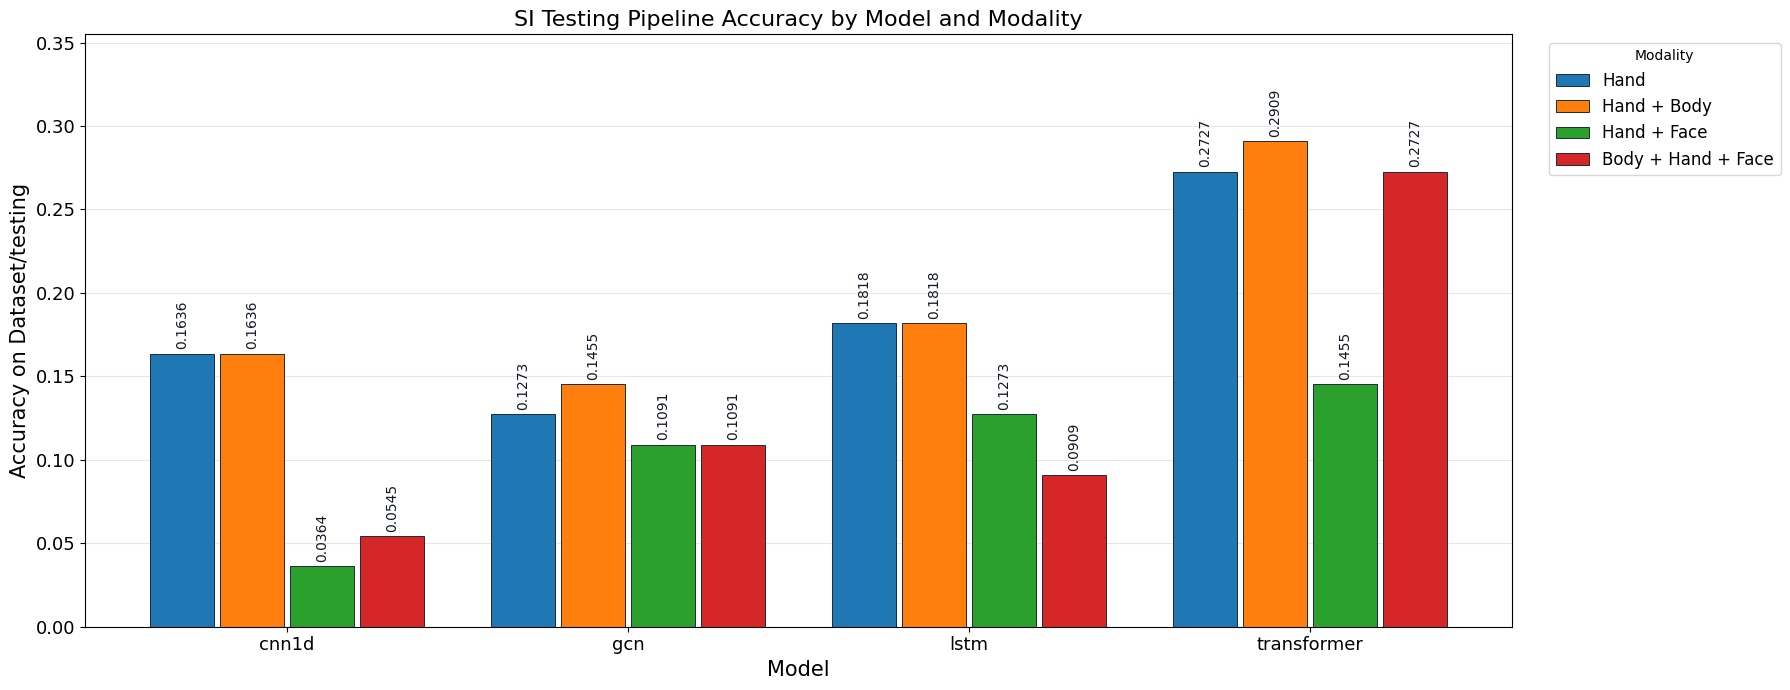

Saved artifacts/testing_pipeline_all_models/testing_pipeline_si_all_modalities_macro_f1_bar.png


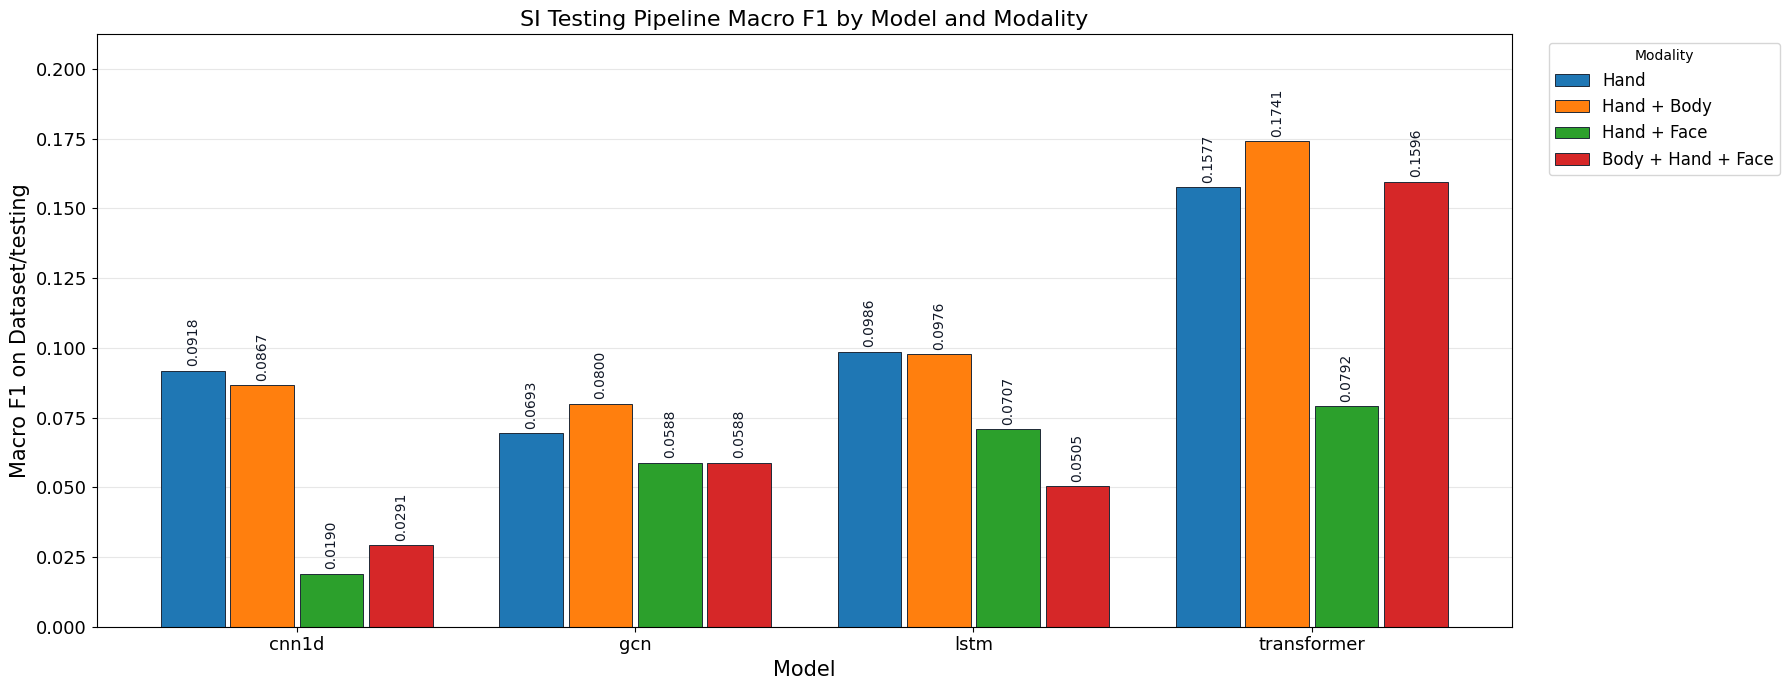

In [27]:
testing_metric_df = (
    summary_df.assign(
        scenario=lambda df: df["scenario"].str.upper(),
        accuracy=lambda df: pd.to_numeric(df["accuracy"], errors="coerce"),
        macro_f1=lambda df: pd.to_numeric(df["macro_f1"], errors="coerce"),
    )
    [["scenario", "model", "modality", "frame_sample_count", "run_id", "videos", "successful", "errors", "accuracy", "macro_f1", "mean_confidence"]]
    .sort_values(["model", "modality", "scenario"])
    .reset_index(drop=True)
)

display(
    testing_metric_df.style.format(
        {"accuracy": "{:.4f}", "macro_f1": "{:.4f}", "mean_confidence": "{:.4f}"},
        na_rep="",
    )
)

model_order = [model for model in ["cnn1d", "gcn", "lstm", "transformer"] if model in set(testing_metric_df["model"])]
modality_order = [
    modality
    for modality in ["hand", "hand_body", "hand_face", "body_hand_face"]
    if modality in set(testing_metric_df["modality"])
]
modality_labels = {
    "hand": "Hand",
    "hand_body": "Hand + Body",
    "hand_face": "Hand + Face",
    "body_hand_face": "Body + Hand + Face",
}
modality_colors = dict(zip(modality_order, plt.cm.tab10.colors[: len(modality_order)]))


def plot_testing_metric_bars(metric_column: str, title: str, ylabel: str, output_name: str) -> None:
    fig, ax = plt.subplots(figsize=(18, 7))
    x_positions = list(range(len(model_order)))
    bar_group_width = 0.82
    bar_width = bar_group_width / max(1, len(modality_order))
    metric_max = 0.0

    metric_pivot = (
        testing_metric_df.pivot_table(
            index="model",
            columns="modality",
            values=metric_column,
            aggfunc="first",
            observed=False,
        )
        .reindex(index=model_order, columns=modality_order)
    )

    for modality_index, modality in enumerate(modality_order):
        offsets = [position - bar_group_width / 2 + bar_width / 2 + modality_index * bar_width for position in x_positions]
        values = [metric_pivot.loc[model, modality] for model in model_order]
        metric_max = max(metric_max, max([value for value in values if pd.notna(value)], default=0.0))
        bars = ax.bar(
            offsets,
            values,
            width=bar_width * 0.92,
            color=modality_colors.get(modality, "#94a3b8"),
            edgecolor="#1f2937",
            linewidth=0.7,
            label=modality_labels.get(modality, modality),
            zorder=2,
        )
        labels = [f"{value:.4f}" if pd.notna(value) else "" for value in values]
        ax.bar_label(bars, labels=labels, padding=3, fontsize=10, color="#111827", rotation=90)

    ax.set_title(title, fontsize=16)
    ax.set_ylabel(ylabel, fontsize=15)
    ax.set_xlabel("Model", fontsize=15)
    ax.set_xticks(x_positions)
    ax.set_xticklabels(model_order, fontsize=13)
    ax.tick_params(axis="y", labelsize=13)
    ax.set_ylim(0, max(0.05, min(1.0, metric_max * 1.22)))
    ax.grid(axis="y", alpha=0.3, zorder=1)
    ax.legend(title="Modality", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=12)
    fig.tight_layout()

    output_path = OUTPUT_DIR / output_name
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    print(f"Saved {output_path}")
    plt.show()


plot_testing_metric_bars(
    "accuracy",
    "SI Testing Pipeline Accuracy by Model and Modality",
    "Accuracy on Dataset/testing",
    "testing_pipeline_si_all_modalities_accuracy_bar.png",
)
plot_testing_metric_bars(
    "macro_f1",
    "SI Testing Pipeline Macro F1 by Model and Modality",
    "Macro F1 on Dataset/testing",
    "testing_pipeline_si_all_modalities_macro_f1_bar.png",
)


## Gesture Correctness, Skeleton Heatmap, Quadrant, And Similarity Analysis

This section analyzes the 16 SI model/modality runs together. It asks which testing gestures are usually predicted correctly, projects each gesture skeleton onto a normalized 2D canvas, summarizes quadrant usage, and compares each gesture to the usually-correct and usually-incorrect skeleton groups.


Gestures analyzed: 55


,video_name,expected_label,total_runs,correct_runs,models_tested,modalities_tested,correct_models,correct_modalities,correct_rate,top_wrong_predictions,correctness_group
0,781021953643841-GREAT.mp4,GREAT,16,13,4,4,"cnn1d, gcn, lstm, transformer","body_hand_face, hand, hand_body, hand_face",0.812,"WEATHER (1), CASTLE2 (1), FENCE2 (1)",usually_correct
1,9399155951019131-VLOG.mp4,VLOG,16,13,4,4,"cnn1d, gcn, lstm, transformer","body_hand_face, hand, hand_body, hand_face",0.812,ZOOMIN (3),usually_correct
2,360022648103667-LICK ENVELOPE_2.mp4,LICKENVELOPE2,16,12,4,4,"cnn1d, gcn, lstm, transformer","body_hand_face, hand, hand_body, hand_face",0.750,"SHIRT2 (1), LAUGH (1), DENY (1)",usually_correct
3,767795376798134-SCISSORS.mp4,SCISSORS,16,12,4,4,"cnn1d, gcn, lstm, transformer","body_hand_face, hand, hand_body, hand_face",0.750,"RUNFAUCET (2), LIGHTER (1), SELF (1)",usually_correct
4,9565952168189491-FORBID.mp4,FORBID,16,9,4,4,"cnn1d, gcn, transformer","body_hand_face, hand, hand_body, hand_face",0.562,"INSPIRE (1), ASSIST (1), WANT2 (1)",usually_correct
5,12448238042056992-SEQUENCE.mp4,SEQUENCE,16,9,4,4,"cnn1d, gcn, lstm, transformer","body_hand_face, hand, hand_body, hand_face",0.562,"SALAD (1), MOVE (1), ORDER1 (1)",usually_correct
6,9639829625128289-REGISTER.mp4,REGISTER,16,8,4,4,"gcn, lstm, transformer","body_hand_face, hand, hand_body, hand_face",0.500,"EASEL (3), LABEL (2), MINE (1)",usually_correct
7,5400254175733363-CROWN.mp4,CROWN,16,5,4,4,"cnn1d, lstm, transformer","hand, hand_body",0.312,"HEADACHE (6), BLINK (2), BASKETBALL1 (1)",usually_incorrect
8,019809089337332608-HEAP.mp4,HEAP,16,5,4,4,"cnn1d, lstm, transformer","body_hand_face, hand, hand_body",0.312,"STAFF (2), KNIGHT1 (1), FAIL (1)",usually_incorrect
9,7179536700594904-CHERISH.mp4,CHERISH,16,4,4,4,"lstm, transformer","body_hand_face, hand_body, hand_face",0.250,"SANDWICH1 (8), EASEL (1), HARMONICA (1)",usually_incorrect


Usually correct gestures


,video_name,expected_label,total_runs,correct_runs,models_tested,modalities_tested,correct_models,correct_modalities,correct_rate,top_wrong_predictions,correctness_group
0,781021953643841-GREAT.mp4,GREAT,16,13,4,4,"cnn1d, gcn, lstm, transformer","body_hand_face, hand, hand_body, hand_face",0.812,"WEATHER (1), CASTLE2 (1), FENCE2 (1)",usually_correct
1,9399155951019131-VLOG.mp4,VLOG,16,13,4,4,"cnn1d, gcn, lstm, transformer","body_hand_face, hand, hand_body, hand_face",0.812,ZOOMIN (3),usually_correct
2,360022648103667-LICK ENVELOPE_2.mp4,LICKENVELOPE2,16,12,4,4,"cnn1d, gcn, lstm, transformer","body_hand_face, hand, hand_body, hand_face",0.750,"SHIRT2 (1), LAUGH (1), DENY (1)",usually_correct
3,767795376798134-SCISSORS.mp4,SCISSORS,16,12,4,4,"cnn1d, gcn, lstm, transformer","body_hand_face, hand, hand_body, hand_face",0.750,"RUNFAUCET (2), LIGHTER (1), SELF (1)",usually_correct
4,9565952168189491-FORBID.mp4,FORBID,16,9,4,4,"cnn1d, gcn, transformer","body_hand_face, hand, hand_body, hand_face",0.562,"INSPIRE (1), ASSIST (1), WANT2 (1)",usually_correct
5,12448238042056992-SEQUENCE.mp4,SEQUENCE,16,9,4,4,"cnn1d, gcn, lstm, transformer","body_hand_face, hand, hand_body, hand_face",0.562,"SALAD (1), MOVE (1), ORDER1 (1)",usually_correct
6,9639829625128289-REGISTER.mp4,REGISTER,16,8,4,4,"gcn, lstm, transformer","body_hand_face, hand, hand_body, hand_face",0.500,"EASEL (3), LABEL (2), MINE (1)",usually_correct
7,5400254175733363-CROWN.mp4,CROWN,16,5,4,4,"cnn1d, lstm, transformer","hand, hand_body",0.312,"HEADACHE (6), BLINK (2), BASKETBALL1 (1)",usually_incorrect
8,019809089337332608-HEAP.mp4,HEAP,16,5,4,4,"cnn1d, lstm, transformer","body_hand_face, hand, hand_body",0.312,"STAFF (2), KNIGHT1 (1), FAIL (1)",usually_incorrect
9,7179536700594904-CHERISH.mp4,CHERISH,16,4,4,4,"lstm, transformer","body_hand_face, hand_body, hand_face",0.250,"SANDWICH1 (8), EASEL (1), HARMONICA (1)",usually_incorrect


Usually incorrect gestures


,video_name,expected_label,total_runs,correct_runs,models_tested,modalities_tested,correct_models,correct_modalities,correct_rate,top_wrong_predictions,correctness_group
35,22011752227806758-CROWN.mp4,CROWN,16,0,4,4,,,0.000,"MUSTACHE (1), MINE (1), CAMERAMAN (1)",usually_incorrect
36,21604854634666015-DEVELOP.mp4,DEVELOP,16,0,4,4,,,0.000,"SKIRT (4), STRESS (2), PAPER (1)",usually_incorrect
37,18508791786058-GRADUATE1.mp4,GRADUATE1,16,0,4,4,,,0.000,"OLD (3), GRADUATE (2), FALL1 (1)",usually_incorrect
38,10197122928088187-GRENADE.mp4,GRENADE,16,0,4,4,,,0.000,"JUICE1 (2), NIECE (1), AUNT (1)",usually_incorrect
39,19538333263577434-HEAD BACK.mp4,HEADBACK,16,0,4,4,,,0.000,"SLIP1 (1), BRAG (1), SHAVE1 (1)",usually_incorrect
40,37022317180054576-LEFT.mp4,LEFT,16,0,4,4,,,0.000,"DRAG2 (3), DEODORANT (2), PITCHER (1)",usually_incorrect
41,6557016152897002-MISCHIEVOUS.mp4,MISCHIEVOUS,16,0,4,4,,,0.000,"CREWCUT (6), CHEER (3), CASTLE1 (1)",usually_incorrect
42,8192041038033997-OVERNIGHT.mp4,OVERNIGHT,16,0,4,4,,,0.000,"RELIEF (5), CHEERLEADER2 (2), FOLLOW2 (1)",usually_incorrect
43,8628824589580892-REGULAR.mp4,REGULAR,16,0,4,4,,,0.000,"SOMETHING (3), BITEONNECK (2), LEMON2 (2)",usually_incorrect
44,9725091268498984-REQUEST.mp4,REQUEST,16,0,4,4,,,0.000,"COOL2 (2), HOSE (1), COOK (1)",usually_incorrect


,run_key,cnn1d / body_hand_face,cnn1d / hand,cnn1d / hand_body,cnn1d / hand_face,gcn / body_hand_face,gcn / hand,gcn / hand_body,gcn / hand_face,lstm / body_hand_face,lstm / hand,lstm / hand_body,lstm / hand_face,transformer / body_hand_face,transformer / hand,transformer / hand_body,transformer / hand_face
expected_label,video_name,,,,,,,,,,,,,,,,
AGE,41179711943329167-AGE.mp4,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
ANYONE,20647859814734493-ANYONE.mp4,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
BACKUP,08357883202605598-BACK UP.mp4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
BLINK,6380325824767712-BLINK.mp4,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0
BRAVE,7411919121847517-BRAVE.mp4,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0
BREAKDOWN,7784696559962119-BREAK DOWN.mp4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
BUTTER,5643971082972699-BUTTER.mp4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
CASTLE,16570823618121522-CASTLE.mp4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
CHERISH,7179536700594904-CHERISH.mp4,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,1


Saved artifacts/testing_pipeline_all_models/testing_pipeline_si_16run_gesture_correctness_matrix.png


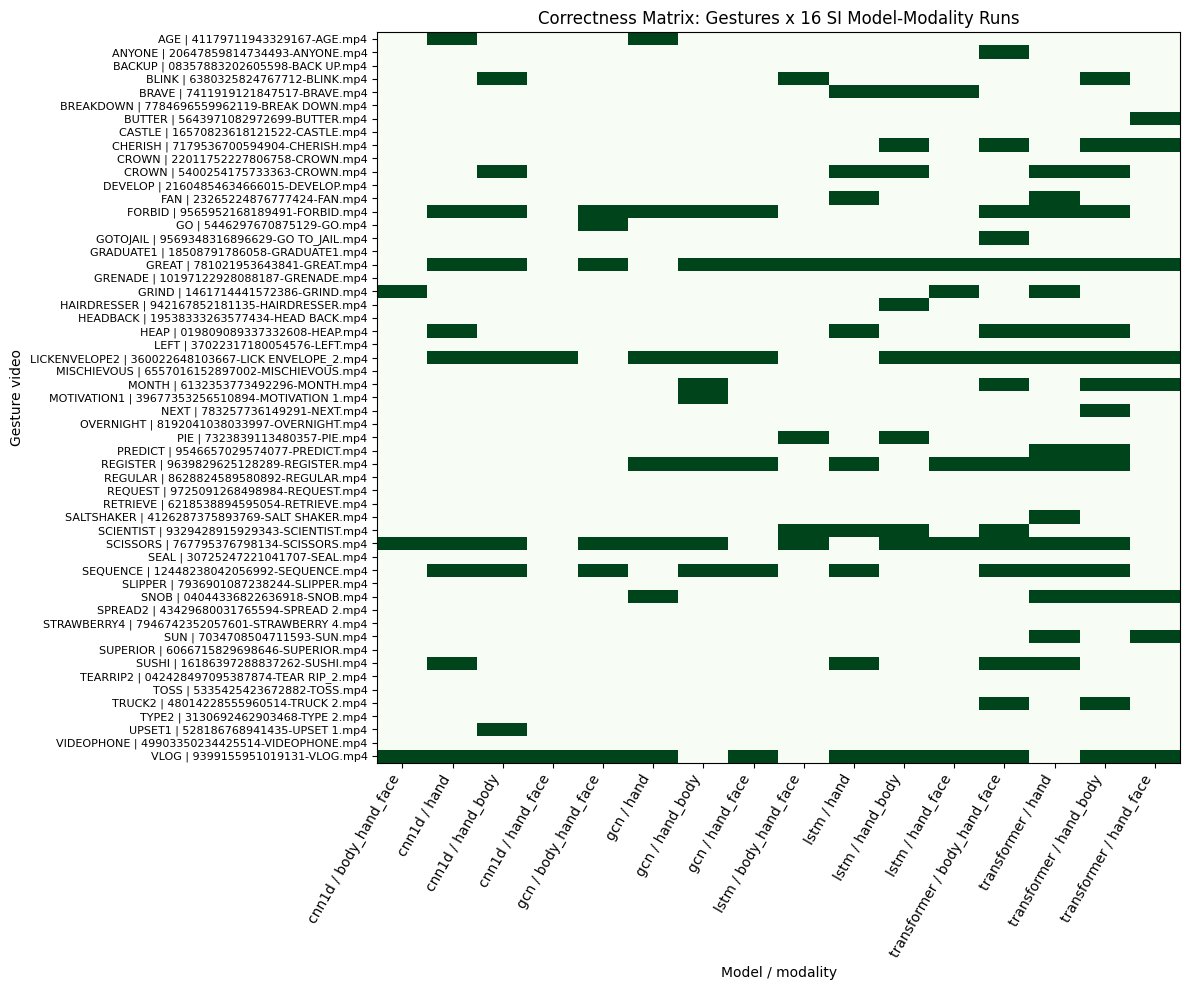

,video_name,expected_label,correct_rate,correctness_group,component,point_count,mean_x,mean_y,std_x,std_y,bbox_width,bbox_height,top_left,top_right,bottom_left,bottom_right
0,781021953643841-GREAT.mp4,GREAT,0.8125,usually_correct,hand,1088,0.519194,0.643736,0.282974,0.239950,0.891170,0.984545,0.117647,0.159007,0.335478,0.387868
1,781021953643841-GREAT.mp4,GREAT,0.8125,usually_correct,body,508,0.555434,0.491824,0.165624,0.192148,0.913577,0.757664,0.155512,0.561024,0.131890,0.151575
2,781021953643841-GREAT.mp4,GREAT,0.8125,usually_correct,face,13862,0.551496,0.379905,0.047528,0.069760,0.232904,0.383181,0.142981,0.799668,0.007503,0.049849
3,9399155951019131-VLOG.mp4,VLOG,0.8125,usually_correct,hand,1071,0.535879,0.680956,0.251837,0.112449,0.765355,0.612885,0.028011,0.044818,0.464052,0.463119
4,9399155951019131-VLOG.mp4,VLOG,0.8125,usually_correct,body,565,0.510615,0.544086,0.173226,0.214993,0.799501,0.671390,0.272566,0.311504,0.217699,0.198230


Average quadrant and canvas profile by correctness group


,correctness_group,component,top_left,top_right,bottom_left,bottom_right,mean_x,mean_y,std_x,std_y,bbox_width,bbox_height
0,usually_correct,body,0.250,0.379,0.190,0.181,0.512,0.503,0.162,0.219,0.829,0.728
1,usually_correct,face,0.388,0.569,0.018,0.026,0.512,0.367,0.050,0.072,0.250,0.373
2,usually_correct,hand,0.040,0.089,0.465,0.406,0.495,0.659,0.185,0.124,0.703,0.592
3,usually_incorrect,body,0.246,0.366,0.169,0.198,0.519,0.494,0.146,0.236,0.736,0.738
4,usually_incorrect,face,0.373,0.544,0.025,0.037,0.513,0.345,0.048,0.072,0.235,0.368
5,usually_incorrect,hand,0.139,0.127,0.280,0.434,0.530,0.637,0.126,0.128,0.509,0.572


Saved artifacts/testing_pipeline_all_models/testing_pipeline_si_skeleton_projection_heatmaps.png


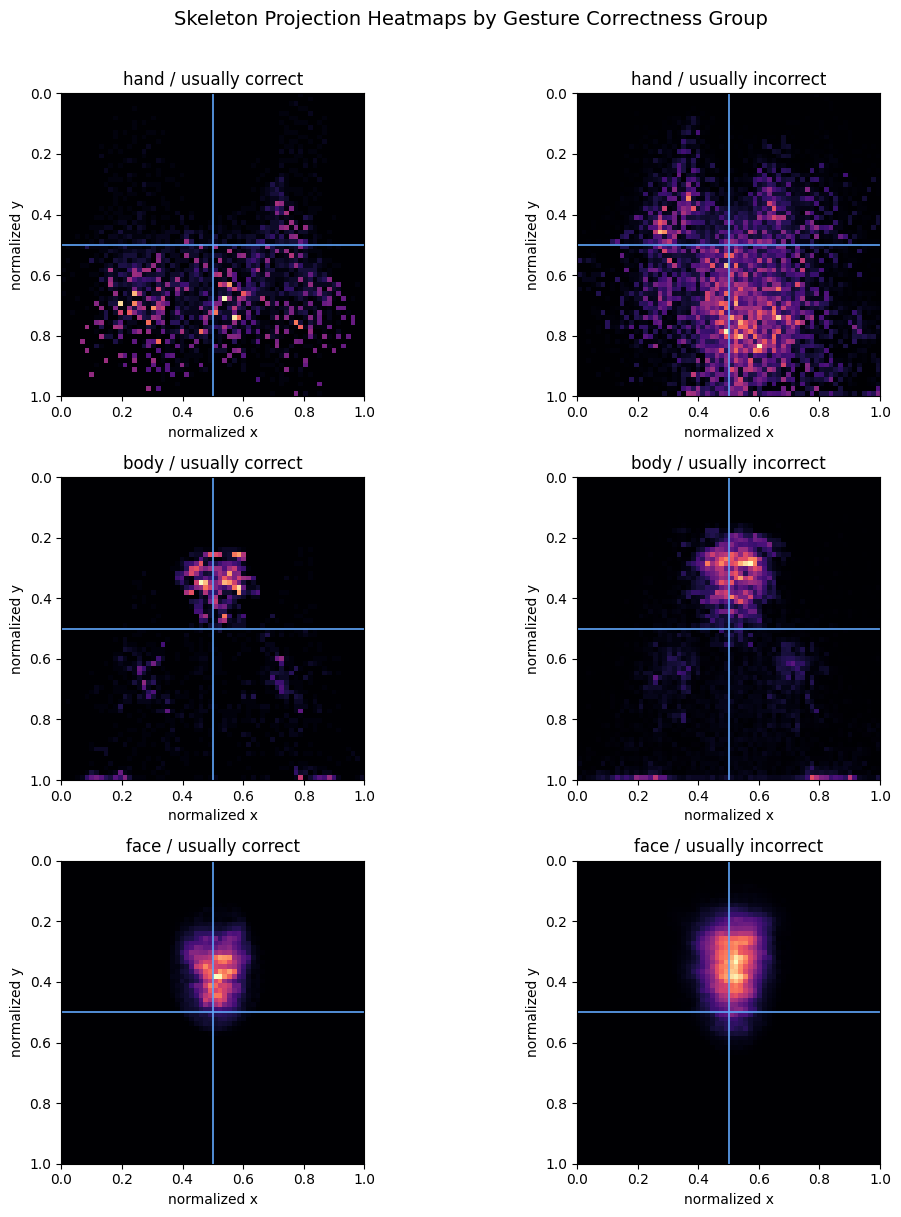

Skeleton-profile similarity to usually-correct vs usually-incorrect groups


,expected_label,video_name,correct_rate,correctness_group,similarity_to_usually_correct,similarity_to_usually_incorrect,similarity_margin
39,SCISSORS,767795376798134-SCISSORS.mp4,0.750,usually_correct,0.911,0.891,0.020
40,BREAKDOWN,7784696559962119-BREAK DOWN.mp4,0.000,usually_incorrect,0.956,0.937,0.019
17,LICKENVELOPE2,360022648103667-LICK ENVELOPE_2.mp4,0.750,usually_correct,0.992,0.977,0.015
51,FORBID,9565952168189491-FORBID.mp4,0.562,usually_correct,0.993,0.979,0.014
31,MONTH,6132353773492296-MONTH.mp4,0.250,usually_incorrect,0.965,0.951,0.014
50,PREDICT,9546657029574077-PREDICT.mp4,0.125,usually_incorrect,0.928,0.914,0.013
5,SEQUENCE,12448238042056992-SEQUENCE.mp4,0.562,usually_correct,0.988,0.976,0.012
48,VLOG,9399155951019131-VLOG.mp4,0.812,usually_correct,0.996,0.985,0.011
1,SNOB,04044336822636918-SNOB.mp4,0.250,usually_incorrect,0.955,0.944,0.011
12,DEVELOP,21604854634666015-DEVELOP.mp4,0.000,usually_incorrect,0.935,0.925,0.009


In [28]:
# Gesture-level correctness across the 16 selected SI model/modality runs
if "results_df" not in globals():
    latest_jsonl = sorted(OUTPUT_DIR.glob("testing_pipeline_predictions_*.jsonl"))[-1]
    results_df = pd.read_json(latest_jsonl, lines=True)
    print(f"Loaded {latest_jsonl}")

analysis_df = results_df.copy()
analysis_df["correct_bool"] = analysis_df["correct"].map({True: True, False: False}).fillna(False)
analysis_df["run_key"] = analysis_df["model"].astype(str) + " / " + analysis_df["modality"].astype(str)
valid_predictions = analysis_df[analysis_df["ok"] & analysis_df["expected_label"].notna()].copy()

def joined_unique(values: pd.Series) -> str:
    unique_values = sorted(str(value) for value in values.dropna().unique())
    return ", ".join(unique_values)


def top_wrong_predictions(group: pd.DataFrame) -> str:
    wrong = group.loc[~group["correct_bool"] & group["prediction"].notna(), "prediction"]
    if wrong.empty:
        return ""
    return ", ".join(f"{label} ({count})" for label, count in wrong.value_counts().head(3).items())


gesture_summary = (
    valid_predictions.groupby(["video_name", "expected_label"], dropna=False)
    .agg(
        total_runs=("run_key", "count"),
        correct_runs=("correct_bool", "sum"),
        models_tested=("model", "nunique"),
        modalities_tested=("modality", "nunique"),
        correct_models=("model", lambda values: joined_unique(valid_predictions.loc[values.index[valid_predictions.loc[values.index, "correct_bool"].to_numpy()], "model"])),
        correct_modalities=("modality", lambda values: joined_unique(valid_predictions.loc[values.index[valid_predictions.loc[values.index, "correct_bool"].to_numpy()], "modality"])),
    )
    .reset_index()
)
gesture_summary["correct_rate"] = gesture_summary["correct_runs"] / gesture_summary["total_runs"]
wrong_prediction_text = (
    valid_predictions.groupby(["video_name", "expected_label"], dropna=False)
    .apply(top_wrong_predictions)
    .rename("top_wrong_predictions")
    .reset_index()
)
gesture_summary = gesture_summary.merge(wrong_prediction_text, on=["video_name", "expected_label"], how="left")
gesture_summary["correctness_group"] = np.where(gesture_summary["correct_rate"] >= 0.5, "usually_correct", "usually_incorrect")
gesture_summary = gesture_summary.sort_values(["correct_rate", "correct_runs", "expected_label"], ascending=[False, False, True]).reset_index(drop=True)

print(f"Gestures analyzed: {len(gesture_summary)}")
display(gesture_summary.style.format({"correct_rate": "{:.3f}"}))

print("Usually correct gestures")
display(gesture_summary.head(20).style.format({"correct_rate": "{:.3f}"}))
print("Usually incorrect gestures")
display(gesture_summary.tail(20).sort_values(["correct_rate", "expected_label"]).style.format({"correct_rate": "{:.3f}"}))

# Per-run view: which gestures each of the 16 model/modality runs gets right.
run_gesture_matrix = (
    valid_predictions.pivot_table(
        index=["expected_label", "video_name"],
        columns="run_key",
        values="correct_bool",
        aggfunc="max",
        fill_value=False,
    )
    .astype(int)
)
display(run_gesture_matrix)

fig, ax = plt.subplots(figsize=(max(12, 0.42 * len(run_gesture_matrix.columns)), max(10, 0.18 * len(run_gesture_matrix))))
ax.imshow(run_gesture_matrix.values, aspect="auto", cmap="Greens", vmin=0, vmax=1)
ax.set_title("Correctness Matrix: Gestures x 16 SI Model-Modality Runs")
ax.set_xlabel("Model / modality")
ax.set_ylabel("Gesture video")
ax.set_xticks(range(len(run_gesture_matrix.columns)))
ax.set_xticklabels(run_gesture_matrix.columns, rotation=60, ha="right")
ax.set_yticks(range(len(run_gesture_matrix.index)))
ax.set_yticklabels([f"{label} | {video}" for label, video in run_gesture_matrix.index], fontsize=8)
fig.tight_layout()
matrix_path = OUTPUT_DIR / "testing_pipeline_si_16run_gesture_correctness_matrix.png"
fig.savefig(matrix_path, dpi=160, bbox_inches="tight")
print(f"Saved {matrix_path}")
plt.show()

# Skeleton projection utilities. Coordinates are normalized onto a 0..1 image canvas; y=0 is top.
SKELETON_ROOT = Path("Dataset/skeleton/30frame")
PROJECTION_COMPONENTS = ("hand", "body", "face")
QUADRANTS = ("top_left", "top_right", "bottom_left", "bottom_right")


def skeleton_component_path(video_name: str, component: str) -> Path:
    return SKELETON_ROOT / component / Path(video_name).with_suffix(".npy")


def load_component_points(video_name: str, component: str) -> np.ndarray:
    path = skeleton_component_path(video_name, component)
    if not path.exists():
        return np.empty((0, 2), dtype=np.float32)
    array = np.load(path, allow_pickle=False)
    if component == "hand" and array.ndim == 4:
        points = array.reshape(-1, array.shape[-1])
    elif array.ndim == 3:
        points = array.reshape(-1, array.shape[-1])
    else:
        return np.empty((0, 2), dtype=np.float32)
    xy = points[:, :2].astype(np.float32, copy=False)
    finite = np.isfinite(xy).all(axis=1)
    nonzero = ~((np.abs(xy[:, 0]) < 1e-8) & (np.abs(xy[:, 1]) < 1e-8))
    in_canvas = (xy[:, 0] >= -0.05) & (xy[:, 0] <= 1.05) & (xy[:, 1] >= -0.05) & (xy[:, 1] <= 1.05)
    xy = xy[finite & nonzero & in_canvas]
    if xy.size == 0:
        return np.empty((0, 2), dtype=np.float32)
    return np.clip(xy, 0.0, 1.0)


def quadrant_profile(points: np.ndarray) -> dict[str, float]:
    if len(points) == 0:
        return {quadrant: 0.0 for quadrant in QUADRANTS}
    x = points[:, 0]
    y = points[:, 1]
    counts = {
        "top_left": int(((x < 0.5) & (y < 0.5)).sum()),
        "top_right": int(((x >= 0.5) & (y < 0.5)).sum()),
        "bottom_left": int(((x < 0.5) & (y >= 0.5)).sum()),
        "bottom_right": int(((x >= 0.5) & (y >= 0.5)).sum()),
    }
    total = max(1, sum(counts.values()))
    return {quadrant: counts[quadrant] / total for quadrant in QUADRANTS}


skeleton_rows = []
for gesture in gesture_summary.itertuples(index=False):
    for component in PROJECTION_COMPONENTS:
        points = load_component_points(gesture.video_name, component)
        profile = quadrant_profile(points)
        if len(points):
            mean_x, mean_y = points.mean(axis=0)
            std_x, std_y = points.std(axis=0)
            min_x, min_y = points.min(axis=0)
            max_x, max_y = points.max(axis=0)
        else:
            mean_x = mean_y = std_x = std_y = min_x = min_y = max_x = max_y = np.nan
        skeleton_rows.append(
            {
                "video_name": gesture.video_name,
                "expected_label": gesture.expected_label,
                "correct_rate": gesture.correct_rate,
                "correctness_group": gesture.correctness_group,
                "component": component,
                "point_count": len(points),
                "mean_x": mean_x,
                "mean_y": mean_y,
                "std_x": std_x,
                "std_y": std_y,
                "bbox_width": max_x - min_x if len(points) else np.nan,
                "bbox_height": max_y - min_y if len(points) else np.nan,
                **profile,
            }
        )

skeleton_df = pd.DataFrame(skeleton_rows)
display(skeleton_df.head())

quadrant_summary = (
    skeleton_df.groupby(["correctness_group", "component"], dropna=False)[list(QUADRANTS) + ["mean_x", "mean_y", "std_x", "std_y", "bbox_width", "bbox_height"]]
    .mean()
    .reset_index()
)
print("Average quadrant and canvas profile by correctness group")
display(quadrant_summary.style.format({column: "{:.3f}" for column in quadrant_summary.columns if column not in {"correctness_group", "component"}}))

# Heatmaps: aggregate projected skeleton points for usually-correct vs usually-incorrect gestures.
def collect_points(video_names: pd.Series, component: str) -> np.ndarray:
    arrays = [load_component_points(video_name, component) for video_name in video_names]
    arrays = [array for array in arrays if len(array)]
    if not arrays:
        return np.empty((0, 2), dtype=np.float32)
    return np.concatenate(arrays, axis=0)


def plot_projection_heatmaps() -> None:
    groups = ["usually_correct", "usually_incorrect"]
    fig, axes = plt.subplots(len(PROJECTION_COMPONENTS), len(groups), figsize=(11, 12), squeeze=False)

    for row_index, component in enumerate(PROJECTION_COMPONENTS):
        for col_index, group_name in enumerate(groups):
            ax = axes[row_index, col_index]
            video_names = gesture_summary.loc[gesture_summary["correctness_group"] == group_name, "video_name"]
            points = collect_points(video_names, component)
            if len(points):
                heatmap, x_edges, y_edges = np.histogram2d(points[:, 0], points[:, 1], bins=64, range=[[0, 1], [0, 1]])
                ax.imshow(
                    heatmap.T,
                    origin="upper",
                    extent=[0, 1, 1, 0],
                    cmap="magma",
                    aspect="equal",
                )
            else:
                ax.text(0.5, 0.5, "No points", ha="center", va="center")
            ax.axvline(0.5, color="#60a5fa", linewidth=1.2)
            ax.axhline(0.5, color="#60a5fa", linewidth=1.2)
            ax.set_xlim(0, 1)
            ax.set_ylim(1, 0)
            ax.set_title(f"{component} / {group_name.replace('_', ' ')}")
            ax.set_xlabel("normalized x")
            ax.set_ylabel("normalized y")

    fig.suptitle("Skeleton Projection Heatmaps by Gesture Correctness Group", y=1.01, fontsize=14)
    fig.tight_layout()
    output_path = OUTPUT_DIR / "testing_pipeline_si_skeleton_projection_heatmaps.png"
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    print(f"Saved {output_path}")
    plt.show()


plot_projection_heatmaps()

# Similarity: compare each gesture's quadrant/centroid feature vector with usually-correct and usually-incorrect centroids.
feature_columns = ["mean_x", "mean_y", "std_x", "std_y", "bbox_width", "bbox_height", *QUADRANTS]
skeleton_feature_wide = (
    skeleton_df.pivot_table(
        index=["video_name", "expected_label", "correct_rate", "correctness_group"],
        columns="component",
        values=feature_columns,
        aggfunc="first",
    )
)
skeleton_feature_wide.columns = [f"{component}_{feature}" for feature, component in skeleton_feature_wide.columns]
skeleton_feature_wide = skeleton_feature_wide.reset_index()
numeric_feature_columns = [column for column in skeleton_feature_wide.columns if column not in {"video_name", "expected_label", "correct_rate", "correctness_group"}]
feature_matrix = skeleton_feature_wide[numeric_feature_columns].fillna(0.0).to_numpy(dtype=float)

def cosine_similarity_to_reference(matrix: np.ndarray, reference: np.ndarray) -> np.ndarray:
    matrix_norm = np.linalg.norm(matrix, axis=1)
    reference_norm = np.linalg.norm(reference)
    denominator = matrix_norm * reference_norm
    denominator[denominator == 0] = np.nan
    return np.nan_to_num((matrix @ reference) / denominator, nan=0.0)


correct_mask = skeleton_feature_wide["correctness_group"] == "usually_correct"
incorrect_mask = skeleton_feature_wide["correctness_group"] == "usually_incorrect"
correct_reference = feature_matrix[correct_mask.to_numpy()].mean(axis=0) if correct_mask.any() else np.zeros(feature_matrix.shape[1])
incorrect_reference = feature_matrix[incorrect_mask.to_numpy()].mean(axis=0) if incorrect_mask.any() else np.zeros(feature_matrix.shape[1])
skeleton_feature_wide["similarity_to_usually_correct"] = cosine_similarity_to_reference(feature_matrix, correct_reference)
skeleton_feature_wide["similarity_to_usually_incorrect"] = cosine_similarity_to_reference(feature_matrix, incorrect_reference)
skeleton_feature_wide["similarity_margin"] = skeleton_feature_wide["similarity_to_usually_correct"] - skeleton_feature_wide["similarity_to_usually_incorrect"]

similarity_columns = [
    "expected_label",
    "video_name",
    "correct_rate",
    "correctness_group",
    "similarity_to_usually_correct",
    "similarity_to_usually_incorrect",
    "similarity_margin",
]
similarity_df = skeleton_feature_wide[similarity_columns].sort_values(["similarity_margin", "correct_rate"], ascending=[False, False])
print("Skeleton-profile similarity to usually-correct vs usually-incorrect groups")
display(similarity_df.style.format({"correct_rate": "{:.3f}", "similarity_to_usually_correct": "{:.3f}", "similarity_to_usually_incorrect": "{:.3f}", "similarity_margin": "{:.3f}"}))


## Sampled Whole-Skeleton Representation Analysis

Centroid trajectories collapse the gesture into one point, so this section uses a fixed sampled skeleton representation instead. Each video becomes a `(30 frames, sampled landmarks, x/y)` sequence for hand, body, and face. The analysis compares usually-correct vs usually-incorrect gestures using point-level motion, quadrant occupancy, and prototype distance over the whole sampled skeleton.


Sampled whole-skeleton feature table


,video_name,expected_label,correct_rate,correctness_group,component,sampled_landmarks,mean_landmark_path_length,max_landmark_path_length,mean_landmark_displacement,max_landmark_displacement,mean_step_motion,mean_spread_x,mean_spread_y,mean_quadrant_transitions,dominant_quadrant,quadrant_top_left,quadrant_top_right,quadrant_bottom_left,quadrant_bottom_right
0,781021953643841-GREAT.mp4,GREAT,0.8125,usually_correct,hand,42,2.179000,3.205872,0.299127,0.644578,0.075138,0.277379,0.105485,3.880952,bottom_right,0.155556,0.140476,0.302381,0.401587
1,781021953643841-GREAT.mp4,GREAT,0.8125,usually_correct,body,33,0.345185,1.309680,0.044903,0.223239,0.011903,0.192763,0.210719,0.606061,bottom_right,0.079798,0.287879,0.165657,0.466667
2,781021953643841-GREAT.mp4,GREAT,0.8125,usually_correct,face,32,0.098384,0.146572,0.010338,0.018202,0.003393,0.064628,0.084269,0.500000,top_right,0.294792,0.593750,0.044792,0.066667
3,9399155951019131-VLOG.mp4,VLOG,0.8125,usually_correct,hand,42,0.658248,0.880800,0.166346,0.364220,0.022698,0.224518,0.082382,1.000000,bottom_right,0.023810,0.038095,0.461111,0.476984
4,9399155951019131-VLOG.mp4,VLOG,0.8125,usually_correct,body,33,0.285152,1.070703,0.028131,0.106789,0.009833,0.163161,0.213623,0.181818,bottom_right,0.155556,0.177778,0.181818,0.484848


Whole-skeleton motion and quadrant profile by correctness group


,correctness_group,component,gestures,mean_path,mean_displacement,mean_step_motion,mean_spread_x,mean_spread_y,mean_quadrant_transitions,top_left,top_right,bottom_left,bottom_right
0,usually_correct,body,7,0.261,0.049,0.009,0.153,0.206,0.381,0.137,0.204,0.175,0.483
1,usually_correct,face,7,0.146,0.024,0.005,0.066,0.085,0.500,0.480,0.436,0.043,0.041
2,usually_correct,hand,7,0.776,0.261,0.027,0.174,0.098,1.585,0.045,0.095,0.380,0.480
3,usually_incorrect,body,48,0.300,0.046,0.010,0.130,0.216,0.526,0.137,0.201,0.152,0.510
4,usually_incorrect,face,48,0.142,0.026,0.005,0.062,0.082,0.478,0.465,0.453,0.032,0.051
5,usually_incorrect,hand,48,0.655,0.181,0.023,0.113,0.103,1.285,0.130,0.115,0.267,0.488


Dominant quadrant counts from sampled skeleton points


dominant_quadrant            bottom_left  bottom_right  top_left  top_right
correctness_group component                                                
usually_correct   body                 0             7         0          0
                  face                 0             0         5          2
                  hand                 1             6         0          0
usually_incorrect body                 0            48         0          0
                  face                 0             1        27         20
                  hand                 9            29         4          6

Whole-skeleton prototype distance: positive margin means closer to usually-correct prototypes


,video_name,expected_label,correct_rate,correctness_group,hand_sampled_distance_to_correct,hand_sampled_distance_to_incorrect,body_sampled_distance_to_correct,body_sampled_distance_to_incorrect,face_sampled_distance_to_correct,face_sampled_distance_to_incorrect,mean_sampled_distance_to_correct,mean_sampled_distance_to_incorrect,sampled_distance_margin
0,781021953643841-GREAT.mp4,GREAT,0.812,usually_correct,0.223857,0.302296,0.071814,0.096870,0.048326,0.057877,0.115,0.152,0.038
1,9399155951019131-VLOG.mp4,VLOG,0.812,usually_correct,0.147756,0.188816,0.050993,0.063478,0.032037,0.051375,0.077,0.101,0.024
4,9565952168189491-FORBID.mp4,FORBID,0.562,usually_correct,0.137203,0.179914,0.052403,0.057935,0.036504,0.055324,0.075,0.098,0.022
14,6380325824767712-BLINK.mp4,BLINK,0.188,usually_incorrect,0.205528,0.228191,0.082827,0.095919,0.082048,0.098715,0.123,0.141,0.017
5,12448238042056992-SEQUENCE.mp4,SEQUENCE,0.562,usually_correct,0.196800,0.216600,0.056943,0.072125,0.037945,0.054963,0.097,0.115,0.017
11,9329428915929343-SCIENTIST.mp4,SCIENTIST,0.250,usually_incorrect,0.153867,0.200223,0.063722,0.067938,0.045977,0.034361,0.088,0.101,0.013
27,942167852181135-HAIRDRESSER.mp4,HAIRDRESSER,0.062,usually_incorrect,0.235469,0.283919,0.093896,0.092891,0.075786,0.066471,0.135,0.148,0.013
33,7784696559962119-BREAK DOWN.mp4,BREAKDOWN,0.000,usually_incorrect,0.172304,0.191913,0.073205,0.078443,0.062896,0.063978,0.103,0.111,0.009
23,20647859814734493-ANYONE.mp4,ANYONE,0.062,usually_incorrect,0.255372,0.241708,0.089715,0.104295,0.076924,0.095606,0.141,0.147,0.007
52,5335425423672882-TOSS.mp4,TOSS,0.000,usually_incorrect,0.330354,0.320940,0.098673,0.108851,0.056615,0.071747,0.162,0.167,0.005


Saved artifacts/testing_pipeline_all_models/testing_pipeline_si_sampled_skeleton_prototypes.png


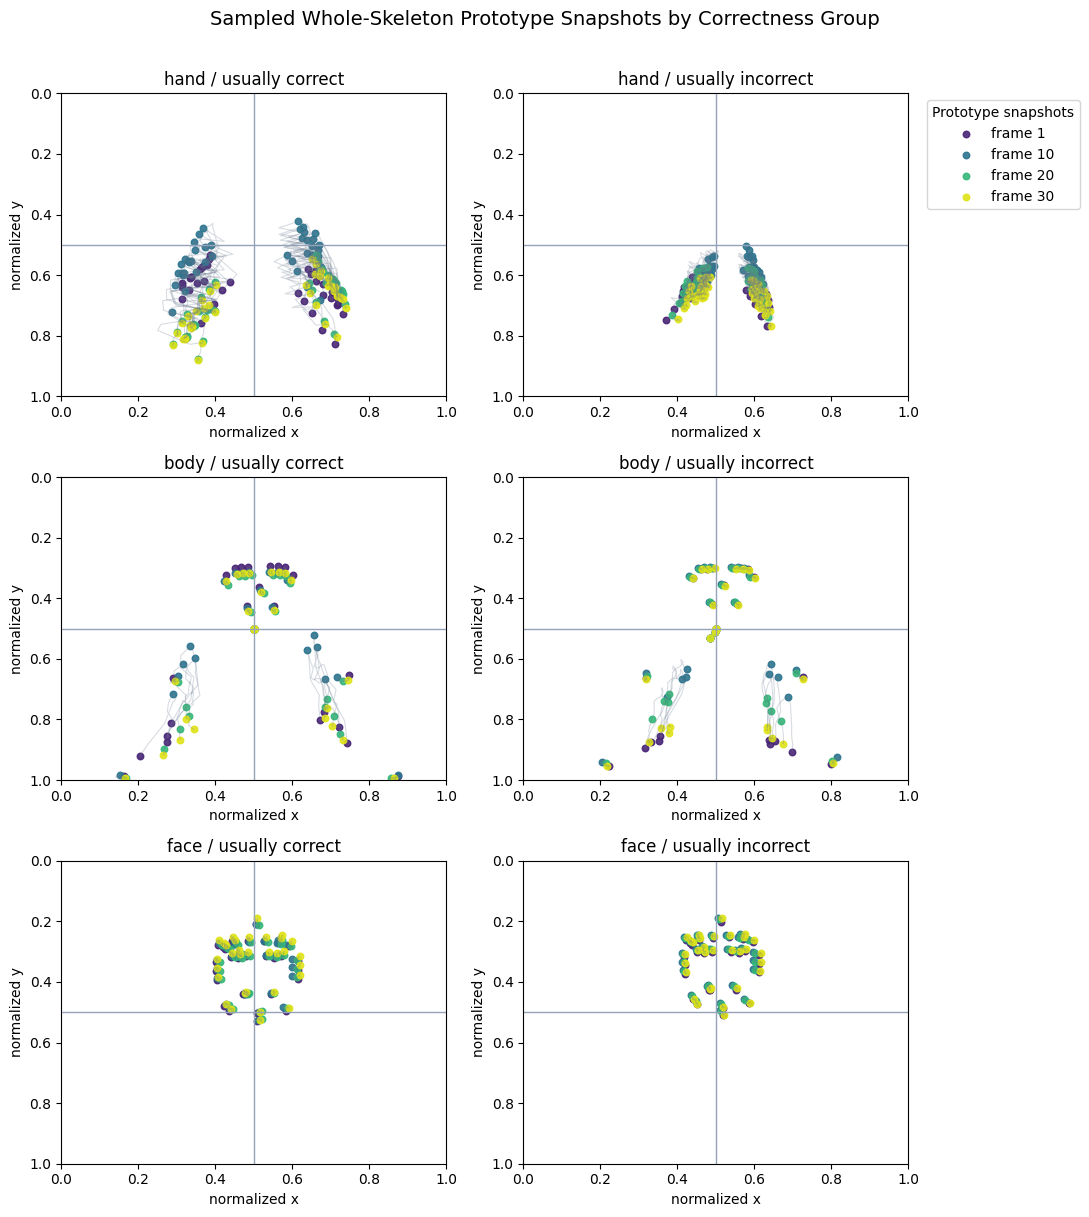

In [29]:
# Sampled whole-skeleton representation over the 30 sampled frames
REPRESENTATION_LENGTH = 30
SAMPLED_LANDMARKS = {
    "hand": list(range(42)),  # both hands, 21 landmarks each
    "body": list(range(33)),  # full pose skeleton
    # Representative face contour, brows, eyes, nose, and mouth points from MediaPipe's 478 landmarks.
    "face": [
        10, 21, 33, 46, 52, 61, 70, 78, 93, 105, 107, 127, 133, 136, 145, 152,
        159, 172, 199, 234, 263, 282, 291, 300, 323, 334, 336, 356, 362, 365, 374, 454,
    ],
}


def load_component_sampled_sequence(video_name: str, component: str, length: int = REPRESENTATION_LENGTH) -> np.ndarray:
    path = skeleton_component_path(video_name, component)
    sample_indices = SAMPLED_LANDMARKS[component]
    sample_count = len(sample_indices)
    sequence = np.full((length, sample_count, 2), np.nan, dtype=float)
    if not path.exists():
        return fill_missing_sequence(sequence)

    array = np.load(path, allow_pickle=False)
    if component == "hand" and array.ndim == 4:
        frame_points = array.reshape(array.shape[0], -1, array.shape[-1])
    elif array.ndim == 3:
        frame_points = array
    else:
        return fill_missing_sequence(sequence)

    valid_indices = [index for index in sample_indices if index < frame_points.shape[1]]
    target_slots = [slot for slot, index in enumerate(sample_indices) if index < frame_points.shape[1]]
    usable_frames = min(length, frame_points.shape[0])
    sampled = frame_points[:usable_frames, valid_indices, :2].astype(float, copy=False)

    finite = np.isfinite(sampled).all(axis=2)
    nonzero = ~((np.abs(sampled[:, :, 0]) < 1e-8) & (np.abs(sampled[:, :, 1]) < 1e-8))
    in_canvas = (
        (sampled[:, :, 0] >= -0.05)
        & (sampled[:, :, 0] <= 1.05)
        & (sampled[:, :, 1] >= -0.05)
        & (sampled[:, :, 1] <= 1.05)
    )
    valid = finite & nonzero & in_canvas
    sampled = np.clip(sampled, 0.0, 1.0)
    sampled[~valid] = np.nan
    sequence[:usable_frames, target_slots, :] = sampled
    return fill_missing_sequence(sequence)


def fill_missing_sequence(sequence: np.ndarray) -> np.ndarray:
    filled = sequence.astype(float, copy=True)
    frame_index = np.arange(filled.shape[0])
    for landmark_index in range(filled.shape[1]):
        for axis in range(2):
            values = filled[:, landmark_index, axis]
            valid = np.isfinite(values)
            if valid.sum() == 0:
                filled[:, landmark_index, axis] = 0.5
            elif valid.sum() == 1:
                filled[:, landmark_index, axis] = values[valid][0]
            else:
                filled[:, landmark_index, axis] = np.interp(frame_index, frame_index[valid], values[valid])
    return np.clip(filled, 0.0, 1.0)


def sequence_quadrants(sequence: np.ndarray) -> np.ndarray:
    x = sequence[:, :, 0]
    y = sequence[:, :, 1]
    quadrants = np.full(x.shape, "bottom_right", dtype=object)
    quadrants[(x < 0.5) & (y < 0.5)] = "top_left"
    quadrants[(x >= 0.5) & (y < 0.5)] = "top_right"
    quadrants[(x < 0.5) & (y >= 0.5)] = "bottom_left"
    return quadrants


def sampled_skeleton_features(sequence: np.ndarray) -> dict[str, float | str]:
    deltas = np.diff(sequence, axis=0)
    landmark_step_distances = np.linalg.norm(deltas, axis=2)
    landmark_path_lengths = landmark_step_distances.sum(axis=0)
    landmark_displacements = np.linalg.norm(sequence[-1] - sequence[0], axis=1)
    frame_spread_x = sequence[:, :, 0].std(axis=1)
    frame_spread_y = sequence[:, :, 1].std(axis=1)
    quadrants = sequence_quadrants(sequence)
    quadrant_counts = pd.Series(quadrants.reshape(-1)).value_counts(normalize=True)
    transition_counts = (quadrants[1:] != quadrants[:-1]).sum(axis=0)
    return {
        "mean_landmark_path_length": float(landmark_path_lengths.mean()),
        "max_landmark_path_length": float(landmark_path_lengths.max()),
        "mean_landmark_displacement": float(landmark_displacements.mean()),
        "max_landmark_displacement": float(landmark_displacements.max()),
        "mean_step_motion": float(landmark_step_distances.mean()),
        "mean_spread_x": float(frame_spread_x.mean()),
        "mean_spread_y": float(frame_spread_y.mean()),
        "mean_quadrant_transitions": float(transition_counts.mean()),
        "dominant_quadrant": str(quadrant_counts.idxmax()) if not quadrant_counts.empty else "unknown",
        **{f"quadrant_{quadrant}": float(quadrant_counts.get(quadrant, 0.0)) for quadrant in QUADRANTS},
    }


sampled_sequence_store = {}
sampled_feature_rows = []
for gesture in gesture_summary.itertuples(index=False):
    for component in PROJECTION_COMPONENTS:
        sequence = load_component_sampled_sequence(gesture.video_name, component)
        sampled_sequence_store[(gesture.video_name, component)] = sequence
        sampled_feature_rows.append(
            {
                "video_name": gesture.video_name,
                "expected_label": gesture.expected_label,
                "correct_rate": gesture.correct_rate,
                "correctness_group": gesture.correctness_group,
                "component": component,
                "sampled_landmarks": sequence.shape[1],
                **sampled_skeleton_features(sequence),
            }
        )

sampled_skeleton_df = pd.DataFrame(sampled_feature_rows)
print("Sampled whole-skeleton feature table")
display(sampled_skeleton_df.head())

sampled_group_summary = (
    sampled_skeleton_df.groupby(["correctness_group", "component"], dropna=False)
    .agg(
        gestures=("video_name", "nunique"),
        mean_path=("mean_landmark_path_length", "mean"),
        mean_displacement=("mean_landmark_displacement", "mean"),
        mean_step_motion=("mean_step_motion", "mean"),
        mean_spread_x=("mean_spread_x", "mean"),
        mean_spread_y=("mean_spread_y", "mean"),
        mean_quadrant_transitions=("mean_quadrant_transitions", "mean"),
        top_left=("quadrant_top_left", "mean"),
        top_right=("quadrant_top_right", "mean"),
        bottom_left=("quadrant_bottom_left", "mean"),
        bottom_right=("quadrant_bottom_right", "mean"),
    )
    .reset_index()
)
print("Whole-skeleton motion and quadrant profile by correctness group")
display(sampled_group_summary.style.format({column: "{:.3f}" for column in sampled_group_summary.columns if column not in {"correctness_group", "component", "gestures"}}))

dominant_quadrant_table = sampled_skeleton_df.pivot_table(
    index=["correctness_group", "component"],
    columns="dominant_quadrant",
    values="video_name",
    aggfunc="count",
    fill_value=0,
    observed=False,
)
print("Dominant quadrant counts from sampled skeleton points")
display(dominant_quadrant_table)

def sampled_prototype(group_name: str, component: str) -> np.ndarray | None:
    video_names = gesture_summary.loc[gesture_summary["correctness_group"] == group_name, "video_name"]
    sequences = [sampled_sequence_store[(video_name, component)] for video_name in video_names if (video_name, component) in sampled_sequence_store]
    if not sequences:
        return None
    return np.stack(sequences, axis=0).mean(axis=0)


def sampled_sequence_distance(sequence: np.ndarray, prototype: np.ndarray | None) -> float:
    if prototype is None:
        return np.nan
    return float(np.linalg.norm(sequence - prototype, axis=2).mean())


sampled_similarity_rows = []
for gesture in gesture_summary.itertuples(index=False):
    row = {
        "video_name": gesture.video_name,
        "expected_label": gesture.expected_label,
        "correct_rate": gesture.correct_rate,
        "correctness_group": gesture.correctness_group,
    }
    correct_distances = []
    incorrect_distances = []
    for component in PROJECTION_COMPONENTS:
        sequence = sampled_sequence_store[(gesture.video_name, component)]
        correct_distance = sampled_sequence_distance(sequence, sampled_prototype("usually_correct", component))
        incorrect_distance = sampled_sequence_distance(sequence, sampled_prototype("usually_incorrect", component))
        row[f"{component}_sampled_distance_to_correct"] = correct_distance
        row[f"{component}_sampled_distance_to_incorrect"] = incorrect_distance
        correct_distances.append(correct_distance)
        incorrect_distances.append(incorrect_distance)
    row["mean_sampled_distance_to_correct"] = float(np.nanmean(correct_distances))
    row["mean_sampled_distance_to_incorrect"] = float(np.nanmean(incorrect_distances))
    row["sampled_distance_margin"] = row["mean_sampled_distance_to_incorrect"] - row["mean_sampled_distance_to_correct"]
    sampled_similarity_rows.append(row)

sampled_similarity_df = pd.DataFrame(sampled_similarity_rows).sort_values(["sampled_distance_margin", "correct_rate"], ascending=[False, False])
print("Whole-skeleton prototype distance: positive margin means closer to usually-correct prototypes")
display(sampled_similarity_df.style.format({
    "correct_rate": "{:.3f}",
    "mean_sampled_distance_to_correct": "{:.3f}",
    "mean_sampled_distance_to_incorrect": "{:.3f}",
    "sampled_distance_margin": "{:.3f}",
}))

def plot_sampled_skeleton_prototypes() -> None:
    groups = ["usually_correct", "usually_incorrect"]
    snapshot_frames = [0, 9, 19, 29]
    frame_colors = plt.cm.viridis(np.linspace(0.1, 0.95, len(snapshot_frames)))
    fig, axes = plt.subplots(len(PROJECTION_COMPONENTS), len(groups), figsize=(11, 12), squeeze=False)

    for row_index, component in enumerate(PROJECTION_COMPONENTS):
        for col_index, group_name in enumerate(groups):
            ax = axes[row_index, col_index]
            prototype = sampled_prototype(group_name, component)
            if prototype is not None:
                # Faint landmark paths show the sampled skeleton's movement envelope.
                for landmark_index in range(prototype.shape[1]):
                    ax.plot(prototype[:, landmark_index, 0], prototype[:, landmark_index, 1], color="#64748b", alpha=0.25, linewidth=0.8)
                for frame, color in zip(snapshot_frames, frame_colors):
                    points = prototype[frame]
                    ax.scatter(points[:, 0], points[:, 1], s=22, color=color, label=f"frame {frame + 1}", alpha=0.9)
            else:
                ax.text(0.5, 0.5, "No prototype", ha="center", va="center")
            ax.axvline(0.5, color="#94a3b8", linewidth=1)
            ax.axhline(0.5, color="#94a3b8", linewidth=1)
            ax.set_xlim(0, 1)
            ax.set_ylim(1, 0)
            ax.set_title(f"{component} / {group_name.replace('_', ' ')}")
            ax.set_xlabel("normalized x")
            ax.set_ylabel("normalized y")
            if row_index == 0 and col_index == len(groups) - 1:
                ax.legend(title="Prototype snapshots", bbox_to_anchor=(1.03, 1), loc="upper left")

    fig.suptitle("Sampled Whole-Skeleton Prototype Snapshots by Correctness Group", y=1.01, fontsize=14)
    fig.tight_layout()
    output_path = OUTPUT_DIR / "testing_pipeline_si_sampled_skeleton_prototypes.png"
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    print(f"Saved {output_path}")
    plt.show()


plot_sampled_skeleton_prototypes()


In [30]:
error_df = results_df.loc[~results_df["ok"], ["scenario", "model", "modality", "frame_sample_count", "run_id", "video_name", "error"]]
print(f"Errors: {len(error_df)}")
display(error_df.head(50))


Errors: 0


,scenario,model,modality,frame_sample_count,run_id,video_name,error


## Optional: Run One Case Through The CLI

Use this cell when you want to verify the notebook is invoking the same command-line script behavior for a single video/run pair.

In [31]:
import subprocess
import sys

sample_video = video_df.iloc[0]
sample_run = runs_df.iloc[0]

command = [
    sys.executable,
    "run_testing_pipeline.py",
    str(sample_video["video"]),
    str(sample_run["run_dir"]),
    "--expected-label",
    str(sample_video["expected_label"]),
    "--top-k",
    str(TOP_K),
]

print(" ".join(command))
subprocess.run(command, check=True)


/usr/local/bin/python run_testing_pipeline.py Dataset/testing/019809089337332608-HEAP.mp4 artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z --expected-label HEAP --top-k 5


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1782066126.489509  174356 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782066126.543758  174356 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782066126.572691  174372 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782066126.585194  174376 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782066126.586359  174382 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1782066126.592789  174385 inference_feedback_manager.cc:114] Feedback mana


=== Testing Pipeline Result ===
Video: Dataset/testing/019809089337332608-HEAP.mp4
Run: artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z
Weights: artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z/best.weights.h5
Config: model=cnn1d scenario=si modality=body_hand_face frames=30 input_shape=[30, 2765]
Expected: HEAP
Correct: False
Prediction: KNIGHT1 (0.3248)

Top predictions:
 1. KNIGHT1 [1312] 0.3248
 2. STRIPE [2306] 0.1777
 3. INSULT [1239] 0.0493
 4. RESENT [1930] 0.0421
 5. FACULTY [831] 0.0362


CompletedProcess(args=['/usr/local/bin/python', 'run_testing_pipeline.py', 'Dataset/testing/019809089337332608-HEAP.mp4', 'artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z', '--expected-label', 'HEAP', '--top-k', '5'], returncode=0)